# Train Price Stacking Ensembles for Core and Full Variants

Run the matching XGBoost and Extra Trees notebooks first.

In [3]:
%pip install -q pandas scikit-learn joblib matplotlib seaborn

In [4]:
import json
import platform
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import drive
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/demand-forecasting/artifacts/price")
VARIANTS = ("core", "full")
TARGET_COLUMN = "future_weighted_avg_procurement_price_rm_per_kg"
KEYS = ["forecast_origin_month", "target_month", "crop", "location", "forecast_horizon"]
META_FEATURES = ["xgboost_prediction", "etr_prediction"]

def load_aligned(variant, split):
    prediction_dir = ROOT / variant / "predictions"
    xgb = pd.read_csv(prediction_dir / f"xgboost_{split}_predictions.csv", parse_dates=["forecast_origin_month", "target_month"])
    etr = pd.read_csv(prediction_dir / f"etr_{split}_predictions.csv", parse_dates=["forecast_origin_month", "target_month"])
    joined = xgb[KEYS + [TARGET_COLUMN, "xgboost_prediction"]].merge(
        etr[KEYS + [TARGET_COLUMN, "etr_prediction"]].rename(columns={TARGET_COLUMN: "etr_actual"}),
        on=KEYS, validate="one_to_one",
    )
    if not np.allclose(joined[TARGET_COLUMN], joined["etr_actual"]):
        raise ValueError(f"{variant} {split} actual targets do not match.")
    return joined.drop(columns="etr_actual")

def score(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual).sum()
    return {"mae": float(mean_absolute_error(actual, predicted)), "rmse": float(np.sqrt(mean_squared_error(actual, predicted))), "wape": float(np.abs(actual - predicted).sum() / denominator) if denominator else np.nan, "r2": float(r2_score(actual, predicted))}

Mounted at /content/drive


In [5]:
records = []
results = {}
for variant in VARIANTS:
    validation = load_aligned(variant, "validation")
    test = load_aligned(variant, "test")
    stacker = Ridge(alpha=1.0)
    stacker.fit(validation[META_FEATURES], validation[TARGET_COLUMN])
    validation["stacking_prediction"] = np.maximum(stacker.predict(validation[META_FEATURES]), 0)
    test["stacking_prediction"] = np.maximum(stacker.predict(test[META_FEATURES]), 0)
    for split_name, frame in [("validation", validation), ("test", test)]:
        for model, column in {"xgboost": "xgboost_prediction", "extra_trees": "etr_prediction", "stacking": "stacking_prediction"}.items():
            records.append({"model": model, "model_variant": variant, "split": split_name, "forecast_horizon": "overall", "rows": len(frame), **score(frame[TARGET_COLUMN], frame[column])})
            for horizon, group in frame.groupby("forecast_horizon"):
                records.append({"model": model, "model_variant": variant, "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **score(group[TARGET_COLUMN], group[column])})
    model_dir = ROOT / variant / "models"
    prediction_dir = ROOT / variant / "predictions"
    report_dir = ROOT / variant / "reports"
    for directory in [model_dir, prediction_dir, report_dir]:
        directory.mkdir(parents=True, exist_ok=True)
    joblib.dump(stacker, model_dir / "experimental_ridge_stacker.joblib")
    validation.to_csv(prediction_dir / "stacking_validation_comparison.csv", index=False)
    test.to_csv(prediction_dir / "stacking_test_comparison.csv", index=False)
    metadata = {"model": "experimental_ridge_stacker", "model_variant": variant, "requires_air_quality": variant == "full", "requires_fama": variant == "full" if "price" in str(ROOT) else False, "status": "experimental", "meta_features": META_FEATURES, "ridge_intercept": float(stacker.intercept_), "ridge_coefficients": dict(zip(META_FEATURES, map(float, stacker.coef_))), "python": platform.python_version()}
    (report_dir / "stacking_training_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    results[variant] = test

metrics = pd.DataFrame(records)
metrics.to_csv(ROOT / "full_core_model_comparison.csv", index=False)
display(metrics[(metrics["split"] == "test") & (metrics["forecast_horizon"] == "overall")].sort_values(["model_variant", "mae"]))

,model,model_variant,split,forecast_horizon,rows,mae,rmse,wape,r2
39,xgboost,core,test,overall,10584,0.162316,0.211792,0.026761,0.994603
65,stacking,core,test,overall,10584,0.163005,0.212850,0.026875,0.994549
52,extra_trees,core,test,overall,10584,0.171819,0.229401,0.028328,0.993668
117,xgboost,full,test,overall,10584,0.162085,0.211655,0.026723,0.994610
143,stacking,full,test,overall,10584,0.162796,0.212903,0.026840,0.994546
130,extra_trees,full,test,overall,10584,0.171106,0.228427,0.028210,0.993722


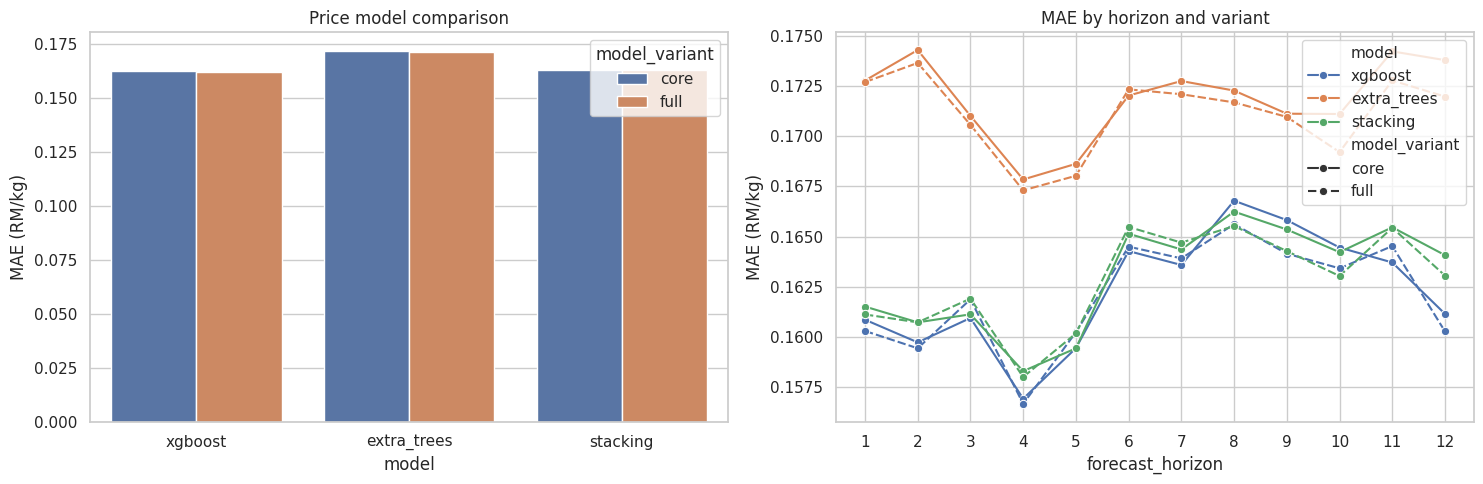

In [6]:
sns.set_theme(style="whitegrid")
overall = metrics[(metrics["split"] == "test") & (metrics["forecast_horizon"] == "overall")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=overall, x="model", y="mae", hue="model_variant", ax=axes[0])
axes[0].set_title("Price model comparison")
axes[0].set_ylabel("MAE (RM/kg)")
horizon = metrics[(metrics["split"] == "test") & (metrics["forecast_horizon"] != "overall")].copy()
horizon["forecast_horizon"] = horizon["forecast_horizon"].astype(int)
sns.lineplot(data=horizon, x="forecast_horizon", y="mae", hue="model", style="model_variant", marker="o", ax=axes[1])
axes[1].set_title("MAE by horizon and variant")
axes[1].set_xticks(range(1, 13))
axes[1].set_ylabel("MAE (RM/kg)")
plt.tight_layout()
plt.show()